<small>Dataset: House Price Prediction Dataset.csv</small>

# Q10. House Price Linear Regression

Predict a numerical house price from property characteristics.


## Question from Classroom

House Price Prediction Using Linear Regression 
Problem statement: Develop a regression model to estimate house prices based on property 
characteristics. 
Dataset: House Price — Kaggle 
Tasks to be performed: 
1. Load a suitable housing dataset. 
2. Perform EDA and identify the input features and target variable. 
3. Handle missing values and encode categorical features if present. 
4. Split the data into training and testing sets. 
5. Train a Linear Regression model. 
6. Predict house prices for the test set. 
7. Evaluate the model using R², RMSE and MAE, and plot actual versus predicted prices.


## Understand before coding

Read -> inspect/plot -> remove identifier -> split -> fill missing values and encode categories -> fit -> evaluate.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 7 listed tasks → 7 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load a suitable housing dataset.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
df=pd.read_csv("data/House Price Prediction Dataset.csv").dropna(subset=["Price"])


## Task 2. Perform EDA and identify the input features and target variable.

This block implements the task above. Variables from earlier blocks are reused.


Shape: (2000, 10)
   Id  Area  Bedrooms  Bathrooms  ...  Location  Condition Garage   Price
0   1  1360         5          4  ...  Downtown  Excellent     No  149919
1   2  4272         5          4  ...  Downtown  Excellent     No  424998
2   3  3592         2          2  ...  Downtown       Good     No  266746
3   4   966         4          2  ...  Suburban       Fair    Yes  244020
4   5  4926         1          4  ...  Downtown       Fair    Yes  636056

[5 rows x 10 columns]
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 

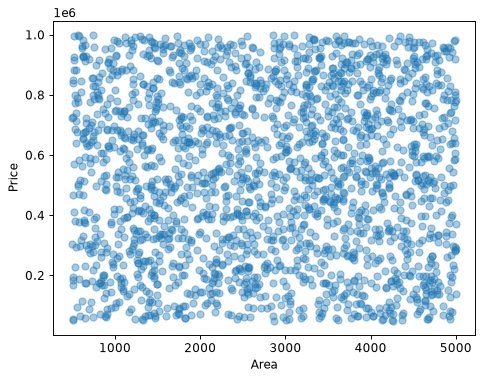

In [2]:
print("Shape:",df.shape)
print(df.head())
df.info()
print("Missing values:\n",df.isna().sum())
print("Summary:\n",df.describe(include="all").T)

plt.scatter(df["Area"],df["Price"],alpha=0.4)
plt.xlabel("Area");plt.ylabel("Price");plt.show()
X=df.drop(columns=["Id","Price"])
y=df["Price"]


## Task 3. Handle missing values and encode categorical features if present.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
numeric=X.select_dtypes(include="number").columns.tolist()
categorical=X.select_dtypes(exclude="number").columns.tolist()
preprocessor=ColumnTransformer([
 ("numeric",SimpleImputer(strategy="median"),numeric),
 ("category",Pipeline([("fill",SimpleImputer(strategy="most_frequent")),
                      ("encode",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),categorical)])
print("Numeric columns:",numeric,"Categorical columns:",categorical)
# Define preprocessing here; FIT it only after the training/test split below.


Numeric columns: ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt'] Categorical columns: ['Location', 'Condition', 'Garage']


## Task 4. Split the data into training and testing sets.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
train_ready=preprocessor.fit_transform(X_train)
test_ready=preprocessor.transform(X_test)


## Task 5. Train a Linear Regression model.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
model=LinearRegression()
model.fit(train_ready,y_train)


## Task 6. Predict house prices for the test set.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
prediction=model.predict(test_ready)
print("First predictions:",prediction[:5])


First predictions: [521988.22189839 549119.31196651 487101.22235594 539752.7439933
 553242.24872512]


## Task 7. Evaluate the model using R², RMSE and MAE, and plot actual versus predicted prices.

This block implements the task above. Variables from earlier blocks are reused.


R2: -0.0067
RMSE: 279859.73
MAE: 243241.98
   Actual      Predicted
0  514764  521988.221898
1  694256  549119.311967
2   66375  487101.222356
3  650243  539752.743993
4  223285  553242.248725
5  468127  521375.920258
6  513002  523320.180806
7  911525  578133.643533
8  723265  545899.647385
9  339416  577368.699406


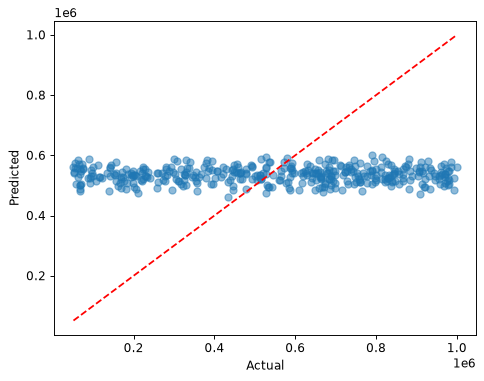

In [7]:
print("R2:",round(r2_score(y_test,prediction),4))
print("RMSE:",round(np.sqrt(mean_squared_error(y_test,prediction)),2))
print("MAE:",round(mean_absolute_error(y_test,prediction),2))
print(pd.DataFrame({"Actual":np.asarray(y_test),"Predicted":prediction}).head(10))

plt.scatter(y_test,prediction,alpha=0.5)
low=min(y_test.min(),prediction.min())
high=max(y_test.max(),prediction.max())
plt.plot([low,high],[low,high],"r--")
plt.xlabel("Actual");plt.ylabel("Predicted");plt.show()


## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What is linear regression?**

It fits y_hat = b0 + b1*x1 + ... + bp*xp, normally by minimizing the sum of squared training residuals.

**10. What are intercept and coefficients?**

The intercept is the predicted value when encoded inputs are zero. A coefficient describes the change in prediction per unit of that feature, holding the others fixed; association does not prove causation.

**11. Define MAE and RMSE.**

MAE=mean(abs(y-y_hat)). RMSE=sqrt(mean((y-y_hat)^2)). Both use the target units; lower is better. RMSE penalizes large errors more strongly.

**12. What is R2?**

R2=1-SSE/SST. A perfect prediction scores 1. A negative score means worse squared error than predicting the test target mean. It is not accuracy or a percentage of correct records.

**13. How do I interpret actual vs predicted?**

Points near the diagonal indicate small errors. Systematic curves or large scatter suggest model limitations. Do not invent a good score when the dataset has weak signal.

**14. Which predictors are available?**

Area, Bedrooms, Bathrooms, Floors, YearBuilt, Location, Condition and Garage. Price is excluded from X and used as y.

**15. Why remove Id?**

It labels a row rather than describing the property. Treating arbitrary identifiers as meaningful predictors can introduce spurious patterns.

**16. Why get_dummies?**

Location, Condition and Garage contain categories. Indicator columns let linear regression use them without assigning an arbitrary numeric ordering.

**17. Why reindex test columns?**

Training may not contain every test category. The fitted model requires exactly the training feature layout and order; an unseen category is represented by zero indicators.

**18. What should the conclusion say?**

Quote the actual held-out R2, RMSE and MAE, describe the prediction scatter, and acknowledge that this dataset may have limited predictive relationships.


### Task-to-code map

- **Block 1:** Load a suitable housing dataset.
- **Block 2:** Perform EDA and identify the input features and target variable.
- **Block 3:** Handle missing values and encode categorical features if present.
- **Block 4:** Split the data into training and testing sets.
- **Block 5:** Train a Linear Regression model.
- **Block 6:** Predict house prices for the test set.
- **Block 7:** Evaluate the model using R², RMSE and MAE, and plot actual versus predicted prices.
